In [ ]:
#TODO(abhi): learn the details its ai generated
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import os
import torch
from stable_baselines3 import SAC
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.callbacks import BaseCallback
from gymnasium.wrappers import TimeLimit
from sim_cart_pole_env import SimCartPoleEnv

# For small network parallelism has kernel overhead
torch.set_num_threads(1)

In [ ]:
# Stable-Baselines3 (SB3) SAC as a benchmark for our discrete SAC
# SB3's SAC only works with continuous actions, CartPole actions are discrete (left, right)
# so SAC outputs a in [-1, 1] and the wrapper turns it into the 3 sim actions, split into 3 equal parts:
# a < -1/3 -> 0 push left, a > 1/3 -> 1 push right, in between -> 2 no push, same physics as our SAC's env
class ContinuousTo3Actions(gym.ActionWrapper):
    def __init__(self, env):
        super().__init__(env)
        self.action_space = gym.spaces.Box(low=-1.0, high=1.0, shape=(1,), dtype=np.float32)

    def action(self, action):
        if action[0] < -1/3:
            return 0
        elif action[0] > 1/3:
            return 1
        return 2


# SB3 trains for a number of steps, not episodes, so this callback counts episodes:
# keeps the reward of every episode, checkpoints every checkpoint_every episodes, stops after num_episodes
class EpisodeCallback(BaseCallback):
    def __init__(self, num_episodes, data_dir, checkpoint_every):
        super().__init__()
        self.num_episodes = num_episodes
        self.data_dir = data_dir
        self.checkpoint_every = checkpoint_every
        self.rewards = []

    def _on_step(self):
        # Monitor adds 'episode' to info when an episode ends, 'r' is the episode reward
        for info in self.locals['infos']:
            if 'episode' in info:
                self.rewards.append(info['episode']['r'])
                n = len(self.rewards)

                if n % 50 == 0:
                    print(f"Run {RUN} | Episode {n}/{self.num_episodes} | Avg Reward (last 50): {np.mean(self.rewards[-50:]):.2f}")

                if n % self.checkpoint_every == 0:
                    path = os.path.join(self.data_dir, f'checkpoint_ep{n:04d}')
                    self.model.save(path)
                    print(f"Checkpoint saved: {path}.zip")

        # returning False stops training
        return len(self.rewards) < self.num_episodes

In [ ]:
# same env and budget as our SAC notebook (06_Soft_Actor_Critic_env2): sim swing up, 2500 episodes, 3 runs
num_episodes = 2500 # per run
num_runs = 3
data_root = 'data_exp004_sb3'
checkpoint_every = 500 # episodes

# enough steps for 2500 episodes of 500 steps, the callback stops at 2500 episodes
total_timesteps = num_episodes * 500

# SB3 SAC with its default settings (no tuned CartPole settings exist for SAC)
# defaults: lr 3e-4, batch 256, gamma 0.99, soft target update tau 0.005, twin critics,
# automatic entropy temperature (ent_coef='auto'), nets [256, 256], train every step
sac_params = dict()

# which runs this notebook trains, all by default, RUNS=2 trains only run 2 (to run them in parallel)
runs_to_train = [int(r) for r in os.environ.get('RUNS', ','.join(str(r) for r in range(1, num_runs + 1))).split(',')]

In [ ]:
for RUN in runs_to_train:
    data_dir = os.path.join(data_root, f'run{RUN}')
    os.makedirs(data_dir, exist_ok=True)
    rewards_path = os.path.join(data_dir, 'reward_per_episode.npy')

    # a finished run is not trained again
    if os.path.exists(rewards_path):
        print(f"Run {RUN} already done, delete {data_dir} to train it again")
        continue

    # Monitor records the reward and length of every episode, the wrapper gives SAC a continuous action
    env = ContinuousTo3Actions(Monitor(TimeLimit(SimCartPoleEnv(), max_episode_steps=500)))
    model = SAC("MlpPolicy", env, verbose=0, **sac_params)

    callback = EpisodeCallback(num_episodes, data_dir, checkpoint_every)
    model.learn(total_timesteps=total_timesteps, callback=callback)

    np.save(rewards_path, np.array(callback.rewards))
    model.save(os.path.join(data_dir, 'sac_final'))
    env.close()

Run 1 | Episode 50/2500 | Avg Reward (last 50): 0.61
Run 1 | Episode 100/2500 | Avg Reward (last 50): 7.96
Run 1 | Episode 150/2500 | Avg Reward (last 50): 127.11
Run 1 | Episode 200/2500 | Avg Reward (last 50): 384.78
Run 1 | Episode 250/2500 | Avg Reward (last 50): 419.23
Run 1 | Episode 300/2500 | Avg Reward (last 50): 420.40
Run 1 | Episode 350/2500 | Avg Reward (last 50): 420.92
Run 1 | Episode 400/2500 | Avg Reward (last 50): 423.02
Run 1 | Episode 450/2500 | Avg Reward (last 50): 423.59
Run 1 | Episode 500/2500 | Avg Reward (last 50): 423.09
Checkpoint saved: data_exp004_sb3/run1/checkpoint_ep0500.zip
Run 1 | Episode 550/2500 | Avg Reward (last 50): 424.32
Run 1 | Episode 600/2500 | Avg Reward (last 50): 424.43
Run 1 | Episode 650/2500 | Avg Reward (last 50): 425.15
Run 1 | Episode 700/2500 | Avg Reward (last 50): 425.22
Run 1 | Episode 750/2500 | Avg Reward (last 50): 424.05
Run 1 | Episode 800/2500 | Avg Reward (last 50): 425.69
Run 1 | Episode 850/2500 | Avg Reward (last 50):

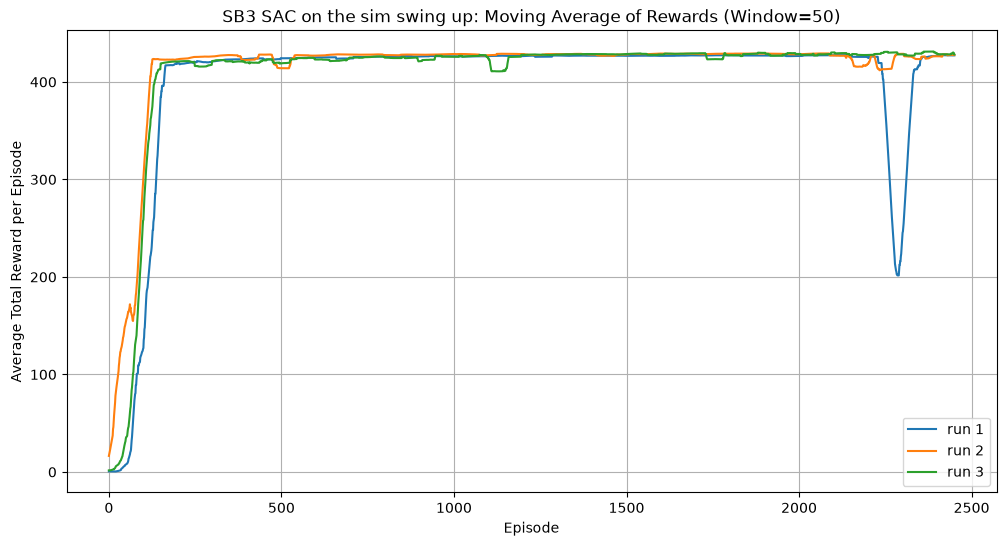

In [ ]:
# plotting the moving average of rewards per episode, all runs
window_size = 50

plt.figure(figsize=(12, 6))
for run in range(1, num_runs + 1):
    rewards = np.load(os.path.join(data_root, f'run{run}', 'reward_per_episode.npy'))
    moving_avg_rewards = np.convolve(rewards, np.ones(window_size)/window_size, mode='valid')
    plt.plot(moving_avg_rewards, label=f'run {run}')
plt.title('SB3 SAC on the sim swing up: Moving Average of Rewards (Window=50)')
plt.xlabel('Episode')
plt.ylabel('Average Total Reward per Episode')
plt.legend()
plt.grid(True)
plt.savefig(os.path.join(data_root, 'moving_avg_all_runs.png'), dpi=100)
plt.show()

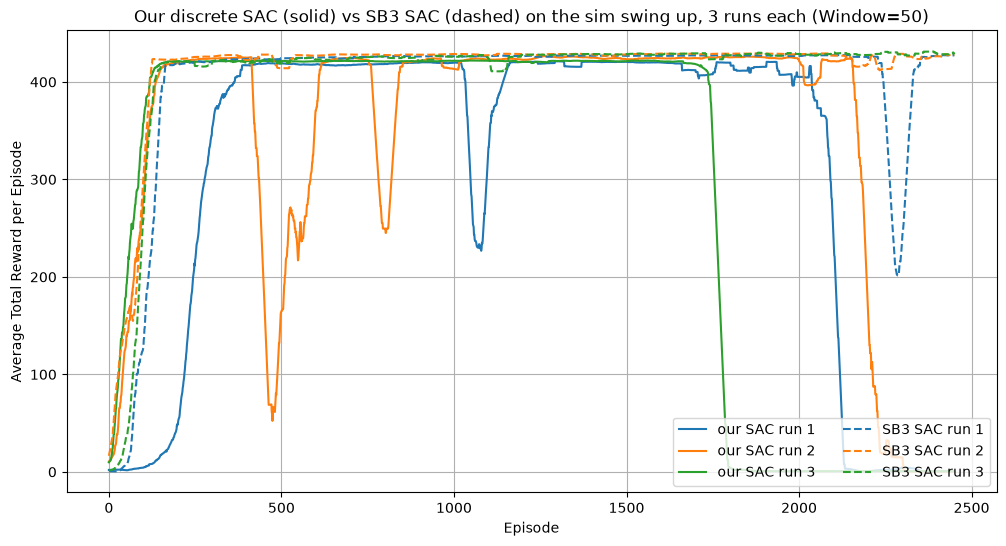

In [ ]:
# compare with our discrete SAC (data_exp004 from 06_Soft_Actor_Critic_env2.ipynb), same window
# one colour per run, our SAC solid, SB3 SAC dashed, saved with the experiment004 write-up in EXPERIMENT.md
colors = ['tab:blue', 'tab:orange', 'tab:green']
plt.figure(figsize=(12, 6))
for name, root, style in [('our SAC', 'data_exp004', '-'), ('SB3 SAC', data_root, '--')]:
    for run in range(1, num_runs + 1):
        path = os.path.join(root, f'run{run}', 'reward_per_episode.npy')
        if not os.path.exists(path):
            continue
        rewards = np.load(path)
        moving_avg_rewards = np.convolve(rewards, np.ones(window_size)/window_size, mode='valid')
        plt.plot(moving_avg_rewards, style, color=colors[run - 1], lw=1.5, label=f'{name} run {run}')
plt.title('Our discrete SAC (solid) vs SB3 SAC (dashed) on the sim swing up, 3 runs each (Window=50)')
plt.xlabel('Episode')
plt.ylabel('Average Total Reward per Episode')
plt.legend(ncol=2, loc='lower right')
plt.grid(True)
os.makedirs(os.path.join('..', 'experiments', 'experiment004'), exist_ok=True)
plt.savefig(os.path.join('..', 'experiments', 'experiment004', 'our_sac_vs_sb3_sac.png'), dpi=100, bbox_inches='tight')
plt.show()

In [ ]:
# Evaluate the learned policy of the last run, greedy (no exploration)
env = ContinuousTo3Actions(TimeLimit(SimCartPoleEnv(), max_episode_steps=500))
model = SAC.load(os.path.join(data_root, f'run{num_runs}', 'sac_final'))

print("Evaluating learned policy...")
total_rewards = 0
num_eval_episodes = 3

for _ in range(num_eval_episodes):
    state, info = env.reset()
    terminated = False
    truncated = False
    episode_reward = 0

    while (not terminated and not truncated):
        action, _ = model.predict(state, deterministic=True)
        state, reward, terminated, truncated, info = env.step(action)
        episode_reward += float(reward)

    total_rewards += episode_reward
print(f"Average reward over {num_eval_episodes} evaluation episodes: {total_rewards / num_eval_episodes:.4f}")
env.close()

Evaluating learned policy...


Average reward over 3 evaluation episodes: 415.3079
